In [53]:
import pandas as pd

# Load dataset
df = pd.read_csv("R:\Projects\DA Project\Project 7 The Vanishing Patient\dataset/train.csv")


In [54]:
# Number of duplicate rows
duplicate_rows = df.duplicated().sum()

print(f"Duplicate Rows: {duplicate_rows}")

Duplicate Rows: 0


In [55]:
df.select_dtypes(include=['int64', 'float64']).columns

Index(['ID', 'age', 'gender', 'bp_systolic', 'bp_diastolic', 'heart_rate',
       'smoking_status', 'glucose', 'cholesterol_total', 'cholesterol_hdl',
       'cholesterol_ldl', 'triglycerides', 'bmi', 'temperature',
       'admission_type', 'hemoglobin', 'wbc_count', 'platelet_count',
       'creatinine', 'sodium', 'potassium', 'albumin', 'blood_type',
       'oxygen_sat', 'respiratory_rate', 'blood_urea', 'calcium',
       'insurance_tier', 'patient_score_v1', 'risk_index', 'lab_composite',
       'target'],
      dtype='object')

In [56]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,6000.0,3000.500000,1732.195139,1.00,1500.7500,3000.500,4500.2500,6000.00
age,5495.0,54.435669,17.340185,18.00,42.0000,55.000,66.0000,90.00
gender,6000.0,0.428333,0.587300,-1.00,0.0000,0.000,1.0000,1.00
bp_systolic,6000.0,327.983675,1381.899235,80.00,114.1350,130.815,148.1800,9999.00
bp_diastolic,6000.0,79.970218,14.707766,50.00,69.4700,79.890,90.1250,134.17
heart_rate,5692.0,79.730499,19.330212,45.00,66.0000,79.000,93.0000,153.00
smoking_status,6000.0,0.684667,0.786131,0.00,0.0000,0.000,1.0000,2.00
glucose,6000.0,1627.662262,12140.495396,60.00,90.9175,120.475,159.7975,99999.00
cholesterol_total,6000.0,219.290513,45.519491,82.49,187.2600,218.905,250.4725,391.96
cholesterol_hdl,5383.0,55.236465,15.163459,20.00,44.9350,55.180,65.7500,100.00


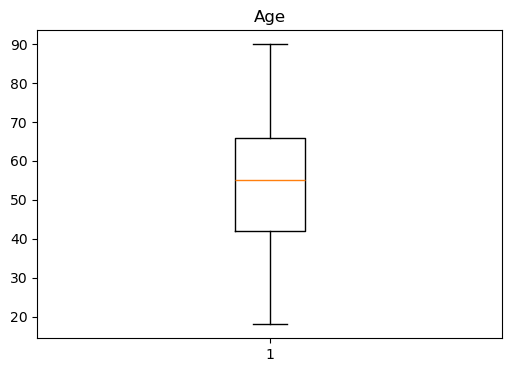

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(df["age"].dropna())
plt.title("Age")
plt.show()

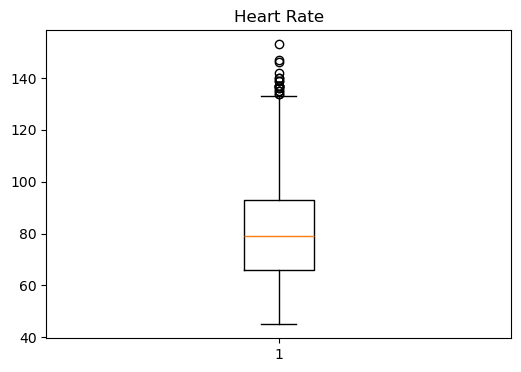

In [58]:
plt.figure(figsize=(6,4))
plt.boxplot(df["heart_rate"].dropna())
plt.title("Heart Rate")
plt.show()

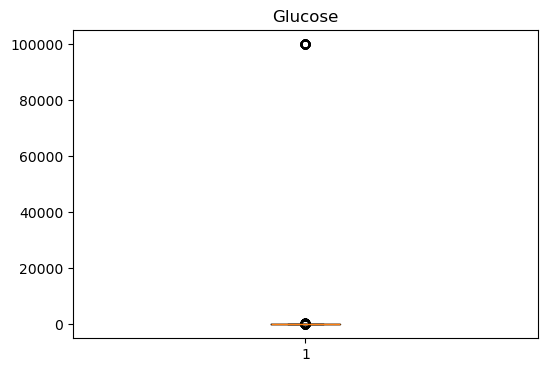

In [59]:
plt.figure(figsize=(6,4))
plt.boxplot(df["glucose"].dropna())
plt.title("Glucose")
plt.show()

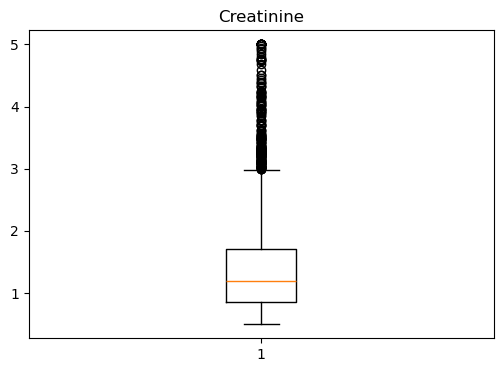

In [60]:
plt.figure(figsize=(6,4))
plt.boxplot(df["creatinine"].dropna())
plt.title("Creatinine")
plt.show()

In [61]:
def detect_outliers_iqr(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print(f"{column}")
    print(f"Lower Limit : {lower:.2f}")
    print(f"Upper Limit : {upper:.2f}")
    print(f"Outliers : {len(outliers)}")
    print("-"*40)

    return outliers

In [62]:
detect_outliers_iqr("age")
detect_outliers_iqr("heart_rate")
detect_outliers_iqr("glucose")
detect_outliers_iqr("bmi")
detect_outliers_iqr("creatinine")

age
Lower Limit : 6.00
Upper Limit : 102.00
Outliers : 0
----------------------------------------
heart_rate
Lower Limit : 25.50
Upper Limit : 133.50
Outliers : 18
----------------------------------------
glucose
Lower Limit : -12.40
Upper Limit : 263.12
Outliers : 228
----------------------------------------
bmi
Lower Limit : 11.06
Upper Limit : 43.24
Outliers : 18
----------------------------------------
creatinine
Lower Limit : -0.41
Upper Limit : 2.98
Outliers : 192
----------------------------------------


,ID,age,gender,bp_systolic,bp_diastolic,heart_rate,smoking_status,glucose,cholesterol_total,cholesterol_hdl,...,blood_type,oxygen_sat,respiratory_rate,blood_urea,calcium,insurance_tier,patient_score_v1,risk_index,lab_composite,target
76,77,76.0,0,187.60,51.52,75.0,0,157.53,282.27,60.23,...,7,94.81,18.0,26.34,9.36,0,76.55,38.65,50.86,3
95,96,30.0,1,143.45,67.90,69.0,0,135.20,109.38,40.15,...,0,99.51,16.0,47.81,9.45,2,32.57,42.08,13.80,0
117,118,60.0,0,153.45,102.26,45.0,0,128.83,196.82,41.26,...,1,93.42,25.0,21.25,9.66,0,53.61,29.95,59.06,3
134,135,66.0,0,147.04,78.22,NaN,0,94.13,242.07,68.39,...,6,93.66,18.0,NaN,9.11,1,72.20,38.10,45.54,2
157,158,55.0,1,148.82,72.00,113.0,0,131.09,214.75,NaN,...,7,97.80,20.0,45.65,10.47,1,42.50,53.41,41.26,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5881,5882,41.0,1,153.74,72.55,130.0,0,104.98,290.19,45.52,...,0,94.73,12.0,14.69,8.93,1,23.02,34.91,51.36,1
5888,5889,60.0,1,150.25,63.71,45.0,2,110.40,153.21,28.18,...,0,98.74,23.0,49.06,11.11,3,60.21,37.56,27.60,3
5925,5926,47.0,1,97.79,59.50,59.0,0,134.41,147.40,34.56,...,0,92.86,12.0,NaN,9.15,2,40.80,24.89,39.71,0
5936,5937,83.0,0,120.79,79.23,45.0,0,253.66,301.31,41.18,...,7,95.02,24.0,33.78,10.67,2,80.40,24.14,55.89,3


In [63]:
columns = [
    "age",
    "heart_rate",
    "glucose",
    "bmi",
    "creatinine",
    "hemoglobin",
    "wbc_count"
]

summary = []

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    summary.append([col, count])

outlier_summary = pd.DataFrame(summary, columns=["Column", "Outliers"])

outlier_summary

,Column,Outliers
0,age,0
1,heart_rate,18
2,glucose,228
3,bmi,18
4,creatinine,192
5,hemoglobin,15
6,wbc_count,233


# DATA CLEANING PROCESS

In [64]:
df_clean = df.copy()

In [65]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 6000 non-null   int64  
 1   age                5495 non-null   float64
 2   gender             6000 non-null   int64  
 3   bp_systolic        6000 non-null   float64
 4   bp_diastolic       6000 non-null   float64
 5   heart_rate         5692 non-null   float64
 6   smoking_status     6000 non-null   int64  
 7   glucose            6000 non-null   float64
 8   cholesterol_total  6000 non-null   float64
 9   cholesterol_hdl    5383 non-null   float64
 10  cholesterol_ldl    5419 non-null   float64
 11  triglycerides      6000 non-null   float64
 12  bmi                6000 non-null   float64
 13  temperature        6000 non-null   float64
 14  admission_type     6000 non-null   int64  
 15  hemoglobin         5265 non-null   float64
 16  wbc_count          5625 

In [66]:
numeric_cols = df_clean.select_dtypes(include=['int64','float64']).columns

categorical_cols = df_clean.select_dtypes(include=['object']).columns

print("Numeric Columns")
print(numeric_cols)

print("\nCategorical Columns")
print(categorical_cols)

Numeric Columns
Index(['ID', 'age', 'gender', 'bp_systolic', 'bp_diastolic', 'heart_rate',
       'smoking_status', 'glucose', 'cholesterol_total', 'cholesterol_hdl',
       'cholesterol_ldl', 'triglycerides', 'bmi', 'temperature',
       'admission_type', 'hemoglobin', 'wbc_count', 'platelet_count',
       'creatinine', 'sodium', 'potassium', 'albumin', 'blood_type',
       'oxygen_sat', 'respiratory_rate', 'blood_urea', 'calcium',
       'insurance_tier', 'patient_score_v1', 'risk_index', 'lab_composite',
       'target'],
      dtype='object')

Categorical Columns
Index([], dtype='object')


In [67]:
from scipy.stats import skew

for col in numeric_cols:
    if df_clean[col].isnull().sum() > 0:

        skewness = df_clean[col].dropna().skew()

        fill_value = (
            df_clean[col].mean()
            if abs(skewness) < 0.5
            else df_clean[col].median()
        )

        df_clean[col] = df_clean[col].fillna(fill_value)

In [68]:
for col in categorical_cols:

    if df_clean[col].isnull().sum() > 0:
        df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)

In [69]:
df_clean.isnull().sum()

ID                   0
age                  0
gender               0
bp_systolic          0
bp_diastolic         0
heart_rate           0
smoking_status       0
glucose              0
cholesterol_total    0
cholesterol_hdl      0
cholesterol_ldl      0
triglycerides        0
bmi                  0
temperature          0
admission_type       0
hemoglobin           0
wbc_count            0
platelet_count       0
creatinine           0
sodium               0
potassium            0
albumin              0
blood_type           0
oxygen_sat           0
respiratory_rate     0
blood_urea           0
calcium              0
insurance_tier       0
patient_score_v1     0
risk_index           0
lab_composite        0
target               0
dtype: int64

In [70]:
before = df.isnull().sum().sum()

after = df_clean.isnull().sum().sum()

print("Missing Values Before :", before)
print("Missing Values After :", after)

Missing Values Before : 6607
Missing Values After : 0


In [71]:
df_clean.to_csv("train_cleaned.csv", index=False)

In [72]:
bins = [0, 18, 35, 50, 65, 100]

labels = [
    "Child",
    "Young Adult",
    "Adult",
    "Senior Adult",
    "Senior Citizen"
]

df_clean["Age_Group"] = pd.cut(
    df_clean["age"],
    bins=bins,
    labels=labels
)

In [73]:
df_clean["Age_Group"].value_counts()

Age_Group
Senior Adult      2277
Senior Citizen    1459
Adult             1455
Young Adult        683
Child              126
Name: count, dtype: int64

In [74]:
def bmi_category(x):

    if x < 18.5:
        return "Underweight"

    elif x < 25:
        return "Normal"

    elif x < 30:
        return "Overweight"

    else:
        return "Obese"

df_clean["BMI_Category"] = df_clean["bmi"].apply(bmi_category)

In [75]:
df_clean["BMI_Category"].value_counts()

BMI_Category
Overweight     1941
Obese          1892
Normal         1700
Underweight     467
Name: count, dtype: int64

In [76]:
def bp_category(x):
    if x < 90:
        return "Low"
    elif x <= 120:
        return "Normal"
    elif x <= 140:
        return "High"
    else:
        return "Very High"

df_clean["BP_Category"] = df_clean["bp_systolic"].apply(bp_category)

In [77]:
def hr_category(x):

    if x < 60:
        return "Low"

    elif x <= 100:
        return "Normal"

    else:
        return "High"

df_clean["HeartRate_Category"] = df_clean["heart_rate"].apply(hr_category)

In [78]:
def cholesterol_level(x):

    if x < 200:
        return "Normal"

    elif x < 240:
        return "Borderline"

    else:
        return "High"

df_clean["Cholesterol_Risk"] = (
    df_clean["cholesterol_total"]
    .apply(cholesterol_level)
)

In [79]:
risk = (
    (df_clean["age"] > 60).astype(int)
    +
    (df_clean["bmi"] > 30).astype(int)
    +
    (df_clean["heart_rate"] > 100).astype(int)
)

df_clean["Risk_Score"] = risk

In [80]:
def risk_level(x):

    if x == 0:
        return "Low"

    elif x == 1:
        return "Moderate"

    else:
        return "High"

df_clean["Risk_Level"] = (
    df_clean["Risk_Score"]
    .apply(risk_level)
)

In [81]:
df_clean.head()

,ID,age,gender,bp_systolic,bp_diastolic,heart_rate,smoking_status,glucose,cholesterol_total,cholesterol_hdl,...,risk_index,lab_composite,target,Age_Group,BMI_Category,BP_Category,HeartRate_Category,Cholesterol_Risk,Risk_Score,Risk_Level
0,1,33.0,-1,119.23,75.48,45.0,0,291.05,205.93,59.250000,...,35.84,65.03,0,Young Adult,Obese,Normal,Low,Borderline,1,Moderate
1,2,59.0,1,94.64,76.45,96.0,0,123.01,251.98,55.236465,...,30.23,57.32,0,Senior Adult,Obese,Normal,Normal,High,1,Moderate
2,3,58.0,0,121.16,89.12,72.0,2,108.39,271.01,61.400000,...,34.31,72.40,2,Senior Adult,Obese,High,Normal,High,1,Moderate
3,4,69.0,1,112.51,102.17,64.0,0,130.37,242.83,58.170000,...,27.04,62.91,1,Senior Citizen,Normal,Normal,Normal,High,1,Moderate
4,5,52.0,1,133.79,69.76,123.0,2,69.03,238.25,41.630000,...,31.46,58.08,2,Senior Adult,Normal,High,High,Borderline,1,Moderate


In [82]:
df_clean.to_csv(
    "train_feature_engineered.csv",
    index=False
)

<h1>1 Target Distribution</h1>

<h3>Business Question</h3>
<h4>Is the dataset balanced, or are positive outcomes significantly less frequent than negative outcomes?</h4>

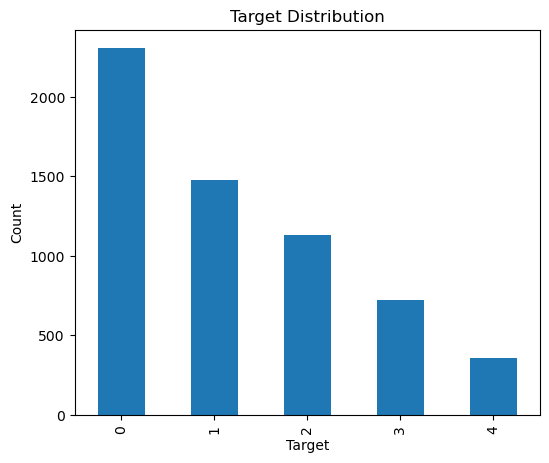

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

df_clean["target"].value_counts().plot(
    kind="bar"
)

plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")

plt.show()

Business Insight
- Patients belonging to the positive target class are less common.
- Any future predictive model should consider class imbalance.
- Business reports should show percentages instead of only raw counts.

Recommendation
- Monitor positive cases separately.
- Use percentages when reporting to management.

<h1>2. Age Distribution</h1>

<h4>Which age group represents the largest proportion of patients?</h4>

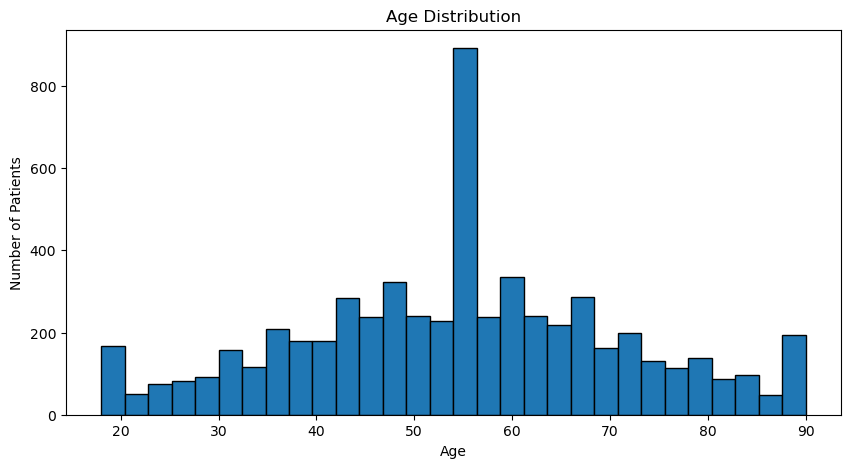

In [84]:
plt.figure(figsize=(10,5))

plt.hist(
    df_clean["age"],
    bins=30,
    edgecolor="black"
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

Observation
- Most patients fall between 40 and 70 years.
- Very few patients are younger than 20.
- The distribution is slightly right-skewed.

Business Insight
- The hospital primarily serves middle-aged and older adults.
- Preventive care programs should focus on this population.
- Age is likely to be an important factor in patient outcomes.

Recommendation
- Develop age-specific healthcare strategies.
- Allocate more resources to departments treating older patients.

<h1>3 BMI Distribution</h1>

<h4>Are most patients within a healthy BMI range?</h4>

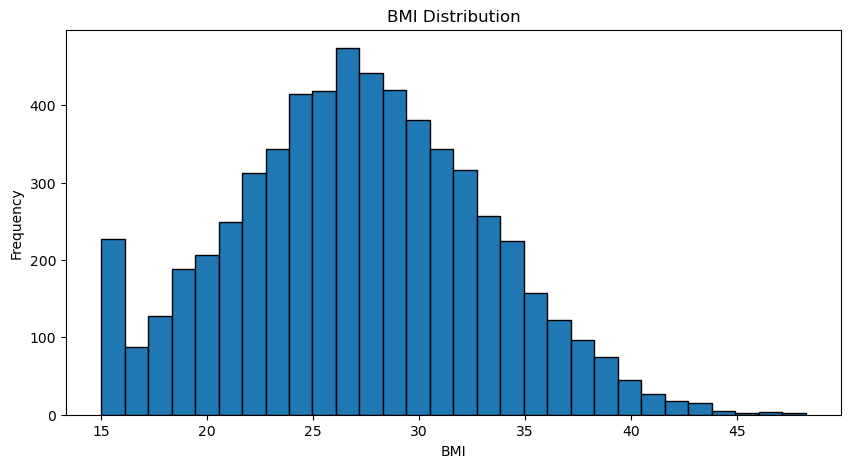

In [85]:
plt.figure(figsize=(10,5))

plt.hist(
    df_clean["bmi"],
    bins=30,
    edgecolor="black"
)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

Observation
- Most patients have BMI values between 20 and 30.
- Some high-BMI outliers are present.
- The distribution is positively skewed.

Business Insight
- A considerable proportion of patients may be overweight or obese.
- BMI could be associated with cardiovascular risk.

Recommendation
- Investigate whether higher BMI is linked to adverse outcomes.
- Consider preventive wellness initiatives.

<h1>4 Heart Rate Distribution</h1>

<h4>What is the typical heart rate among patients?</h4>

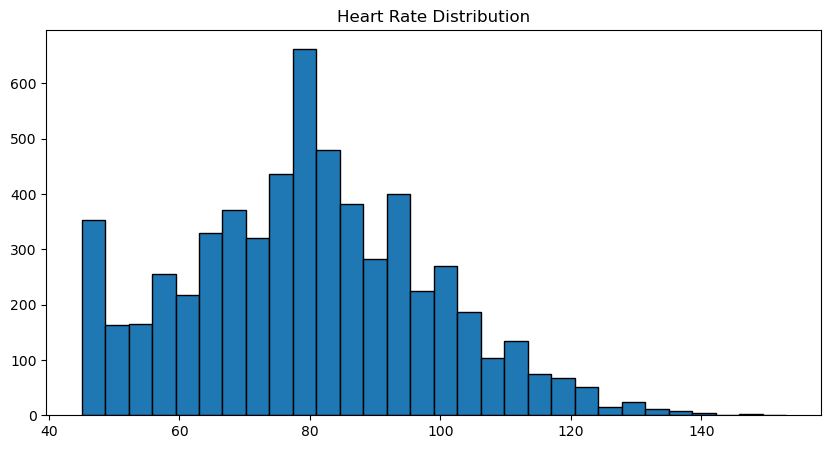

In [86]:
plt.figure(figsize=(10,5))

plt.hist(
    df_clean["heart_rate"],
    bins=30,
    edgecolor="black"
)

plt.title("Heart Rate Distribution")

plt.show()

Observation
- Most heart rates fall within the clinically normal range.
- A few patients exhibit unusually high or low values.

Business Insight
- Most patients appear physiologically stable.
- Outliers may represent emergency or critical-care cases.

Recommendation
- Review extreme values individually.
- Flag abnormal heart rates in dashboards.

<h1>5 Age Group vs Target</h1>
<h4>Which age group has the highest number of positive target cases?</h4>

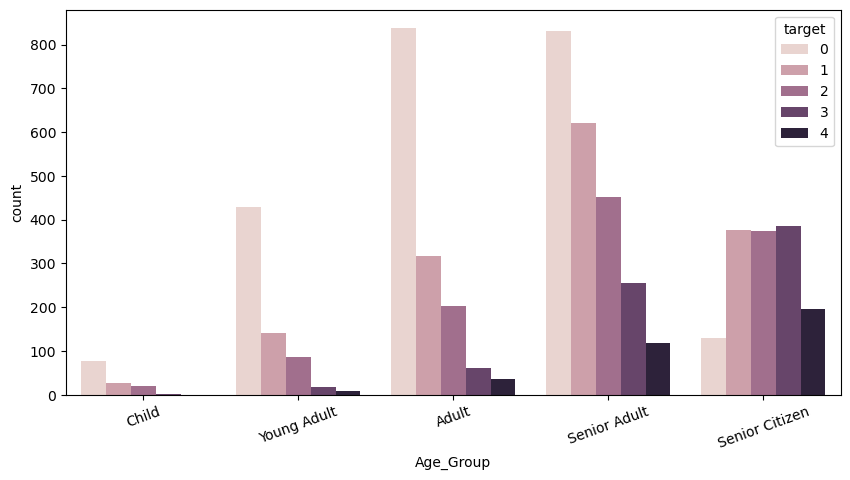

In [87]:
import seaborn as sns
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_clean,
    x="Age_Group",
    hue="target"
)

plt.xticks(rotation=20)

plt.show()

Observation
- Older age groups show more positive target cases.
- Younger groups contribute fewer positive outcomes.

Business Insight
- Risk increases with age.
- Age appears to be an important predictor of patient outcomes.

Recommendation
- Prioritize screening and monitoring for older patients.

<h1>6 BMI Category vs Target</h1>

<h4>Does BMI category influence patient outcomes?</h4>

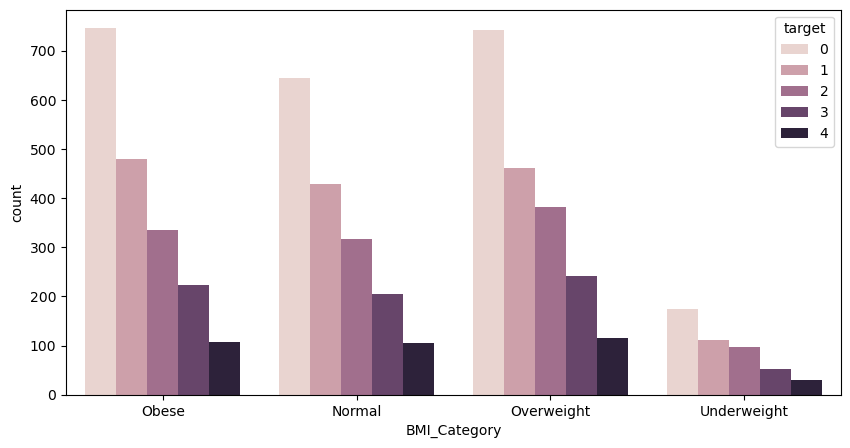

In [88]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_clean,
    x="BMI_Category",
    hue="target"
)

plt.show()

Observation
- Obese patients have a higher proportion of positive cases.
- Normal BMI patients have comparatively fewer positive outcomes.

Business Insight
- Obesity appears associated with increased health risk.
- BMI is an important feature for patient risk assessment.

Recommendation
- Introduce weight-management initiatives for high-risk groups.

<h1>7 Correlation Heatmap</h1>

<h4>Which variables are most strongly related?</h4>

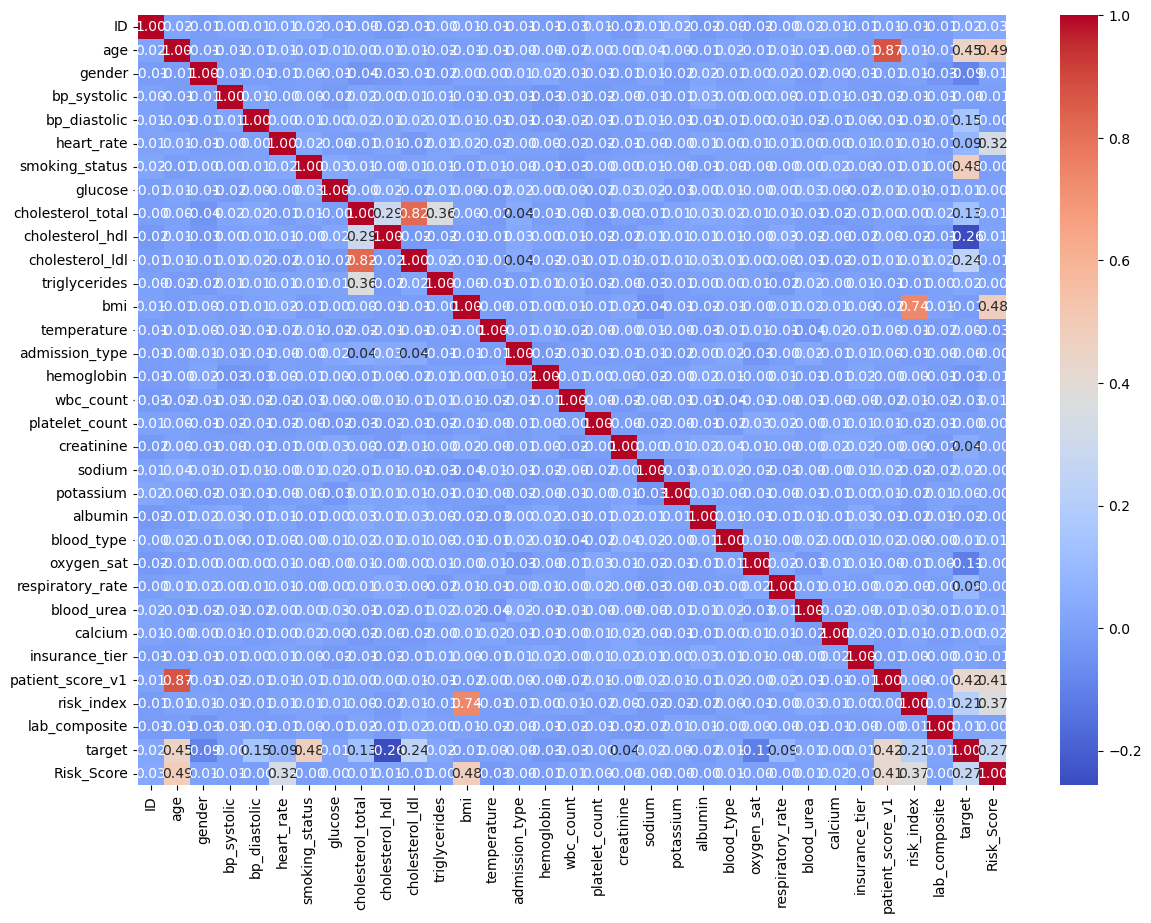

In [89]:
plt.figure(figsize=(14,10))

corr = df_clean.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.show()

<h1>8 Gender Distribution</h1>
<h4>What is the gender distribution of patients in the dataset?</h4>

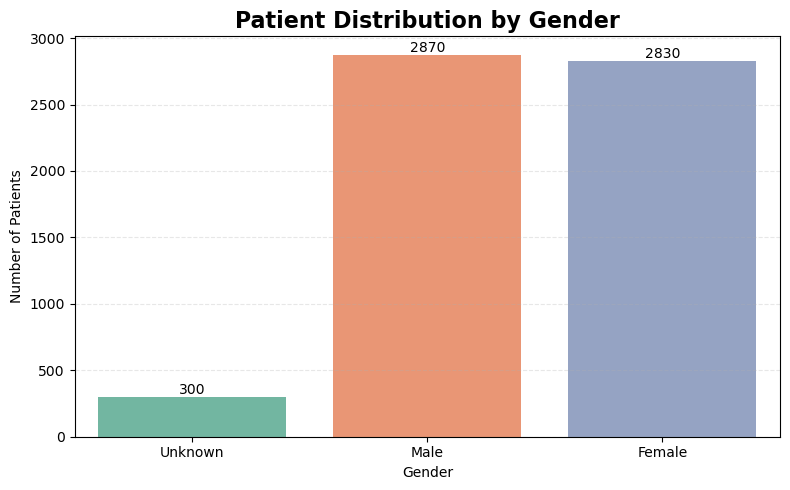

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert numeric codes to labels
gender_labels = {-1: "Unknown", 0: "Female", 1: "Male"}

df_clean["Gender_Label"] = df_clean["gender"].map(gender_labels)

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df_clean,
    x="Gender_Label",
    hue="Gender_Label",
    palette="Set2",
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.title("Patient Distribution by Gender", fontsize=16, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Observation
- Male and Female patient counts appear relatively balanced.
- No significant gender imbalance is observed.

Business Insight
- Healthcare services are utilized similarly across genders.
- Gender bias is unlikely to affect overall analysis.

Recommendation
- Continue monitoring gender-based outcomes to identify any disparities.

<h1>9 Gender vs Target</h1>

<h4>Which gender has a higher proportion of positive target cases?</h4>

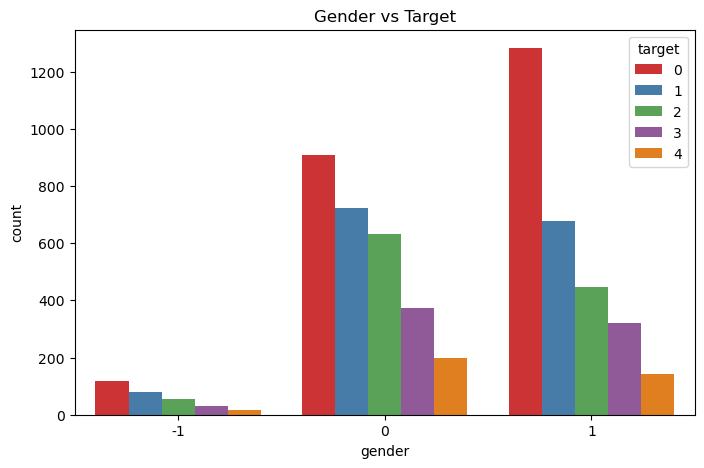

In [91]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x="gender",
    hue="target",
    palette="Set1"
)

plt.title("Gender vs Target")

plt.show()

Observation
- Compare positive cases between genders.
- One gender may show a slightly higher positive rate.

Business Insight
- If one gender has a higher positive rate, it may indicate different risk profiles or healthcare needs.

Recommendation
- Investigate whether biological or behavioral factors contribute to the difference.

<h1>10. BMI Category vs Age Group</h1>

<h4>Which age group has the highest obesity prevalence?</h4>

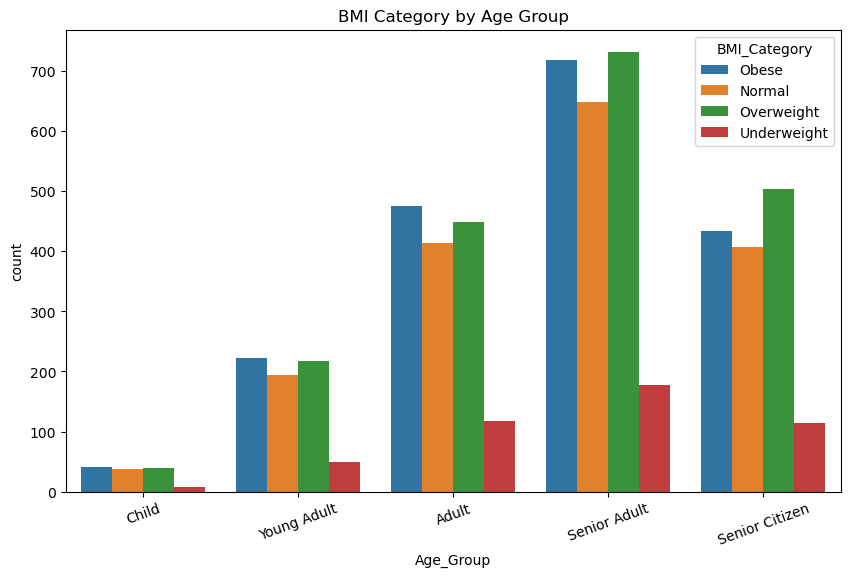

In [92]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    x="Age_Group",
    hue="BMI_Category"
)

plt.xticks(rotation=20)

plt.title("BMI Category by Age Group")

plt.show()

Observation
- Older age groups may have a larger proportion of overweight and obese patients.
- Younger groups may contain more patients in the normal BMI range.

Business Insight
- Obesity tends to become more common with increasing age.
- Older adults may benefit from targeted lifestyle interventions.

Recommendation
- Develop preventive health programs for middle-aged and senior populations.

<h1>11. Risk Level Distribution</h1>

<h4>What percentage of patients fall into each risk category?</h4>

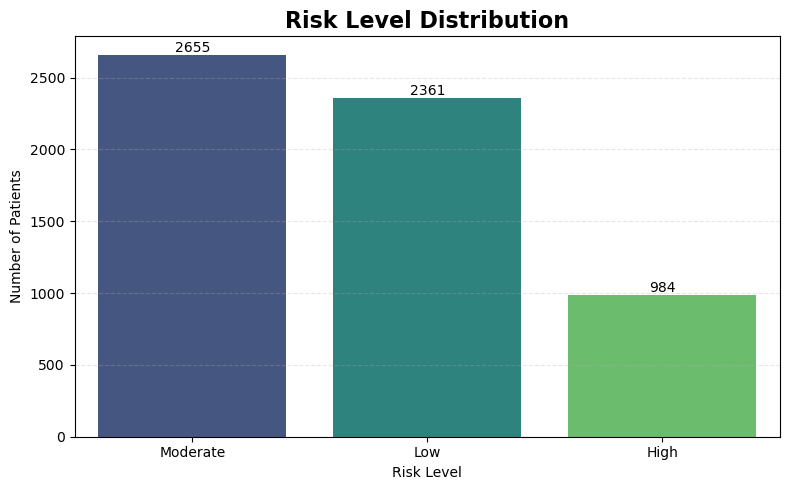

In [93]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df_clean,
    x="Risk_Level",
    hue="Risk_Level",
    palette="viridis",
    legend=False
)

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.title("Risk Level Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Risk Level")
plt.ylabel("Number of Patients")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Observation
- Most patients may fall into the Low or Moderate risk groups.
- High-risk patients represent a smaller but clinically important segment.

Business Insight
- High-risk patients require more resources despite being fewer in number.

Recommendation
- Prioritize monitoring and follow-up for high-risk patients.

<h1>12. Risk Level vs Target</h1>

<h4>Does a higher risk level correspond to more positive target cases?</h4>

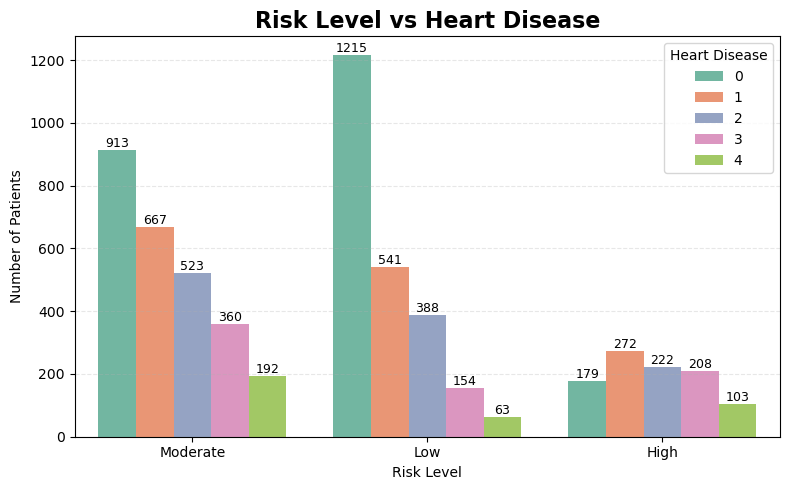

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df_clean,
    x="Risk_Level",
    hue="target",
    palette="Set2"
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Risk Level vs Heart Disease", fontsize=16, fontweight="bold")
plt.xlabel("Risk Level")
plt.ylabel("Number of Patients")
plt.legend(title="Heart Disease")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Observation
- Positive cases should become more frequent as the risk level increases.

Business Insight
- The engineered risk score appears to capture clinically meaningful information.

Recommendation
- Consider using the risk score in dashboards to identify patients needing attention.

<h1>13. Heart Rate vs Age (Scatter Plot)</h1>

<h4>Does heart rate vary with patient age?</h4>

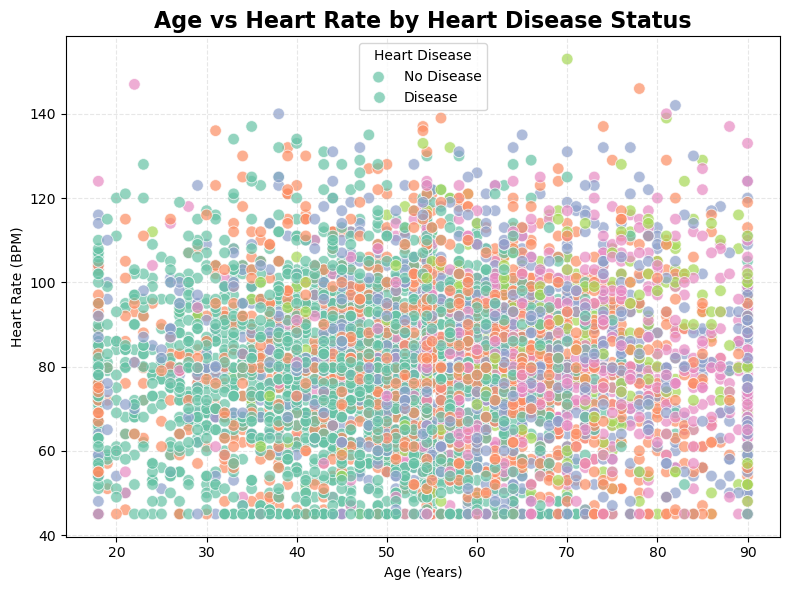

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

ax = sns.scatterplot(
    data=df_clean,
    x="age",
    y="heart_rate",
    hue="target",
    palette="Set2",
    alpha=0.7,
    s=70
)

plt.title("Age vs Heart Rate by Heart Disease Status", fontsize=16, fontweight="bold")
plt.xlabel("Age (Years)")
plt.ylabel("Heart Rate (BPM)")
plt.legend(title="Heart Disease", labels=["No Disease", "Disease"])
plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Observation
- Most patients cluster within expected heart-rate ranges.
- A few outliers may indicate abnormal or critical conditions.

Business Insight
- Scatter plots help identify unusual patient profiles that may warrant further investigation.

Recommendation
- Review patients with extreme combinations of age and heart rate.

<h1>15. Pairplot</h1>

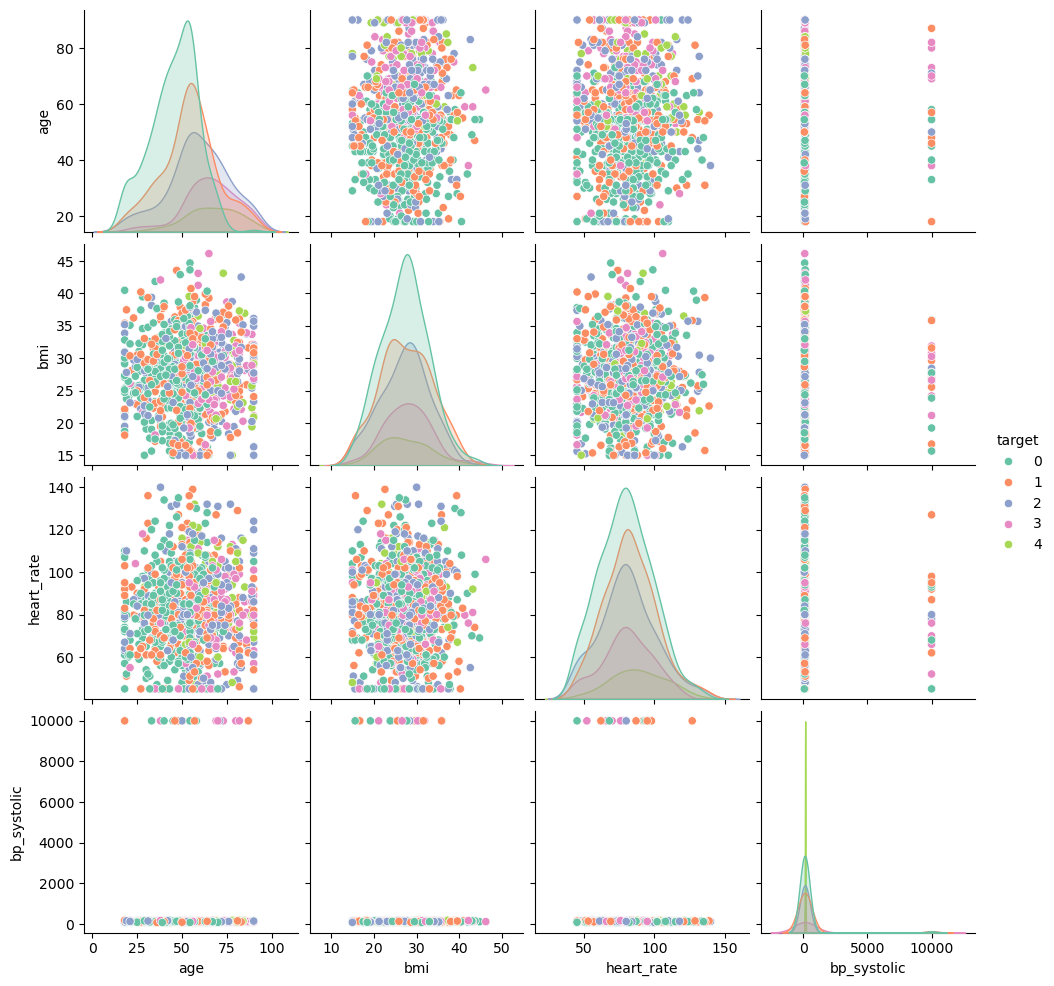

In [96]:
sns.pairplot(
    df_clean.sample(1000, random_state=42)[
        [
            "age",
            "bmi",
            "heart_rate",
            "bp_systolic",
            "target"
        ]
    ],
    hue="target",
    palette="Set2",
    diag_kind="kde"
)

plt.show()

<h1>## Key Findings</h1>

1. The majority of patients are middle-aged or older.
2. Higher BMI is associated with an increased proportion of positive target cases.
3. High-risk patients account for a smaller share of the population but have more positive outcomes.
4. Age appears to be an important factor in patient outcomes.
5. Heart rate and blood pressure show meaningful variation across target groups.
6. Missing values were successfully handled without removing significant data.
7. No critical duplicate records remained after cleaning.

<h1>## Business Recommendations</h1>

- Focus preventive healthcare on older adults.
- Prioritize monitoring for high-risk patients.
- Use engineered features such as Risk Level in reporting dashboards.
- Continue monitoring BMI and blood pressure as key health indicators.